In [77]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Simulating motion

### 1.1 Equations of motion (open loop)

$\ddot{x}=a(r^2-x^2-y^2)x - bv_y$

$\ddot{y}=a(r^2-x^2-y^2)y + bv_x$

Your equations will be more complex and in 3D or might different quantities (angles, etc.).

In [78]:
b = 0.8 # units are [1/s]
a = 0.5 #[1/s^2/m^2]
r2 = 1  #[m^2]

def get_acceleration(position, velocity, time): #can be angular position and angular velocity
    x,y = position #should be in 3D [m]
    vx,vy = velocity # [m/s]

    ax = a*(r2 - x**2 - y**2)*x - b*vy #equations of motion (could be a function of time too)
    #m/s^2 = 1/s^2/m^2*(m^2 - m^2 - m^2)*m - 1/s*m/s    UNITS CHECK
    ay = a*(r2 - x**2 - y**2)*y + b*vx #(tip: check units here)

    acceleration = np.array([ax, ay]) #[m/s^2] 
    return acceleration

### 1.1 Initialization

In [79]:
N = 1000 #number of timesteps
dt = 0.01 #timsteps in seconds

positions = np.empty((N, 2)) #N by 2 arrays to store positions an velocity
velocities = np.empty((N, 2))

positions[0] = np.random.normal(0,3,2) #random initla poisiton (2D vector, normally distributed with zero mean and standard devication of 3 m)
velocities[0] = np.random.normal(0,0.3,2)

### 1.2 Time propagation (Euler's Method)

In [80]:
for i in range(N - 1):
  t = i * dt
  x = positions[i]
  v = velocities[i]
  k1_x = v
  k1_v = get_acceleration(x, v, t)
  k2_x = v + 0.5 * dt * k1_v
  k2_v = get_acceleration(
      x + 0.5 * dt * k1_x, v + 0.5 * dt * k1_v, t + 0.5 * dt
  )

  k3_x = v + 0.5 * dt * k2_v
  k3_v = get_acceleration(
      x + 0.5 * dt * k2_x, v + 0.5 * dt * k2_v, t + 0.5 * dt
  )


  k4_x = v + dt * k3_v
  k4_v = get_acceleration(x + dt * k3_x, v + dt * k3_v, t + dt)

  # Update position and velocity using the weighted average of the steps
  positions[i + 1] = x + (dt / 6.0) * (k1_x + 2 * k2_x + 2 * k3_x + k4_x)
  velocities[i + 1] = v + (dt / 6.0) * (k1_v + 2 * k2_v + 2 * k3_v + k4_v)

### 1.3 Plotting

Text(0, 0.5, 'y [m]')

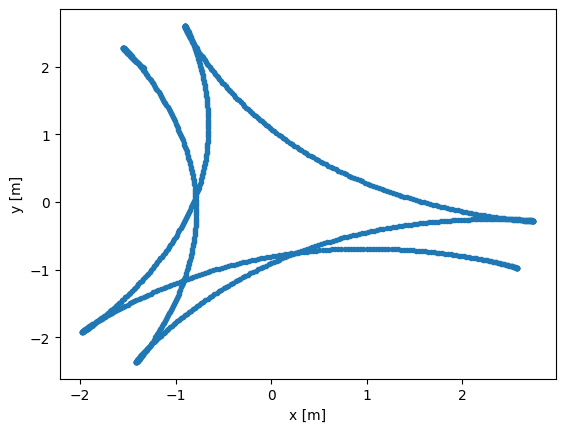

In [81]:
plt.scatter(positions[:,0], positions[:,1], marker=".")
plt.xlabel("x [m]")
plt.ylabel("y [m]")

### 1.4 Putting everything together

Text(0, 0.5, 'y [m]')

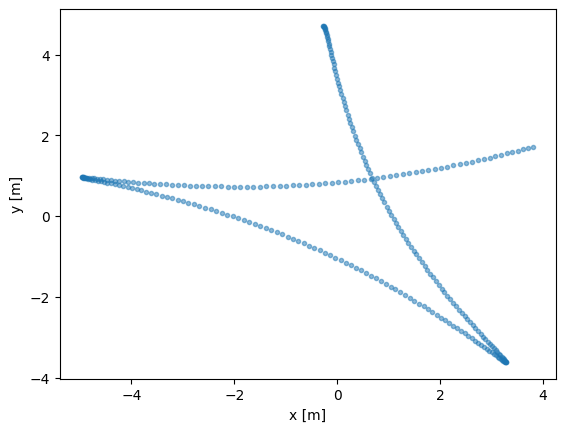

In [82]:
dt = 0.01
t_end = 3 #[s]

N = int(t_end/dt)
positions = np.empty((N, 2))
velocities = np.empty((N, 2))

positions[0] = np.random.normal(0,3,2) #IMPORTANT FOR TESTING
velocities[0] = np.random.normal(0,0.3,2)

for i in range(N-1):
    acceleration = get_acceleration(positions[i], velocities[i], i*dt)
    positions[i+1] = positions[i] + velocities[i]*dt
    velocities[i+1] = velocities[i] + acceleration*dt

plt.scatter(positions[:,0], positions[:,1], marker=".", alpha=0.5)
plt.xlabel("x [m]")
plt.ylabel("y [m]")


### 1.5 Sanity check

The results shouldn't be sensitive to shoice of a simulation (non-physical) parameter $\Delta t$

Text(0, 0.5, 'y [m]')

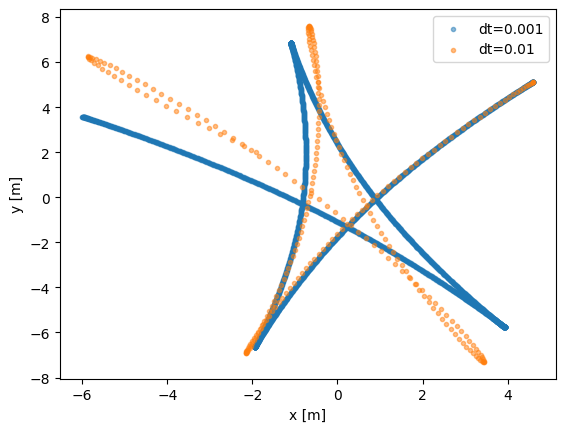

In [83]:
#fix random initial considtions
position_0 = np.random.normal(0,3,2)
velocity_0 = np.random.normal(0,0.3,2)

for dt in [0.001, 0.01]: #simulate with two very different dt
    N = int(t_end/dt)
    positions = np.empty((N, 2))
    velocities = np.empty((N, 2))

    positions[0] = position_0
    velocities[0] = velocity_0

    for i in range(N-1):
        acceleration = get_acceleration(positions[i], velocities[i], i*dt)
        positions[i+1] = positions[i] + velocities[i]*dt
        velocities[i+1] = velocities[i] + acceleration*dt

    plt.scatter(positions[:,0], positions[:,1], marker=".", alpha=0.5, label=f"dt={dt}")

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

## 2 More realistic simulations (random processes)

### 2.1 Random forcing

In [84]:
def get_realistic_acceleration(position, velocity, time, a_std):
    acceleration = get_acceleration(position, velocity, time) #ideal

    random_acceleration = np.random.normal(0, a_std, acceleration.shape) #random acceleration with standard deviation of a_std and the same dimensions as the original acceleration

    return acceleration + random_acceleration

### 2.2 Comparison to the "ideal" case

Text(0, 0.5, 'y [m]')

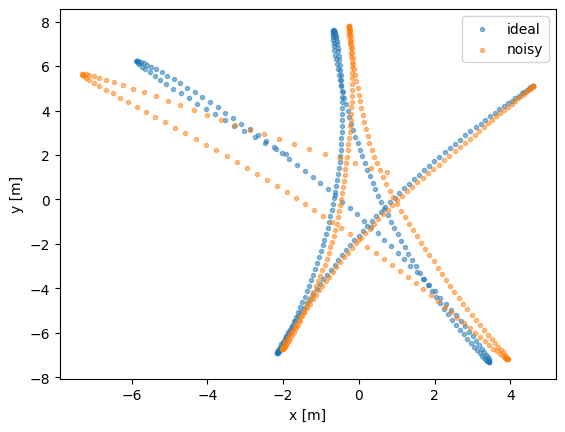

In [85]:
positions_w_rf = np.empty((N, 2)) #store results in arrays different from the "ideal" case
velocities_w_rf = np.empty((N, 2)) #w_rf for with random forcing

positions_w_rf[0] = positions[0] #start with the same initial consitions
velocities_w_rf[0] = velocities[0]

a_std = 30 #[m/s^2] (very large for illustration purposes)

for i in range(N-1):
    acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
    positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
    velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

plt.scatter(positions[:,0], positions[:,1], marker=".", alpha=0.5, label="ideal")
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label="noisy")
plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

### 2.3 Caution: how random forcing scales with $\Delta t$

Keeping random forcing "fixed" gives different behaviour (not insenstitive to $\Delta t$):
The "noise has less effect" when $\Delta t$ is smaller.

Text(0, 0.5, 'y [m]')

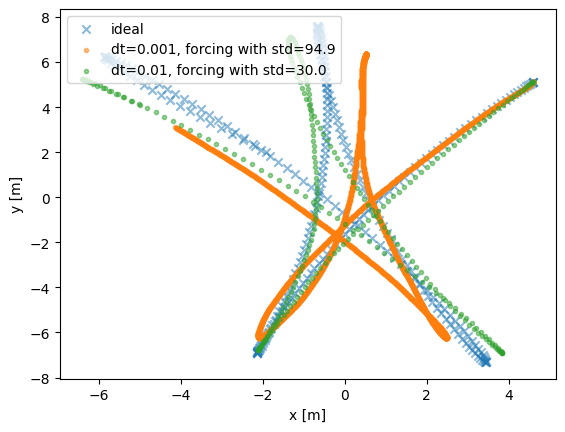

In [94]:
plt.scatter(positions[:, 0], positions[:, 1], marker="x", alpha=0.5, label="ideal")

dt_ref = 0.0001  # Reference dt where a_std = 30 [m/s^2]

for dt in [0.001, 0.01]:  # try two dt
    N = int(3 / dt)  # update number of points
    positions_w_rf = np.empty((N, 2))
    velocities_w_rf = np.empty((N, 2))

    positions_w_rf[0] = positions[0]
    velocities_w_rf[0] = velocities[0]

    # Scale inversely with sqrt(dt) so velocity diffusion is independent of dt
    a_std = 300 * (dt_ref / dt) ** 0.5  # equivalent to 30 / (100 * (dt ** 0.5))

    for i in range(N - 1):
        acceleration_w_rf = get_realistic_acceleration(
            positions_w_rf[i], velocities_w_rf[i], i * dt, a_std
        )
        positions_w_rf[i + 1] = positions_w_rf[i] + velocities_w_rf[i] * dt
        velocities_w_rf[i + 1] = velocities_w_rf[i] + acceleration_w_rf * dt

    plt.scatter(
        positions_w_rf[:, 0],
        positions_w_rf[:, 1],
        marker=".",
        alpha=0.5,
        label=f"dt={dt}, forcing with std={a_std:.1f}",
    )

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

Random acceleration propostional to $\frac{1}{\sqrt{\Delta t}}$ gives the "correct" behavior

Text(0, 0.5, 'y [m]')

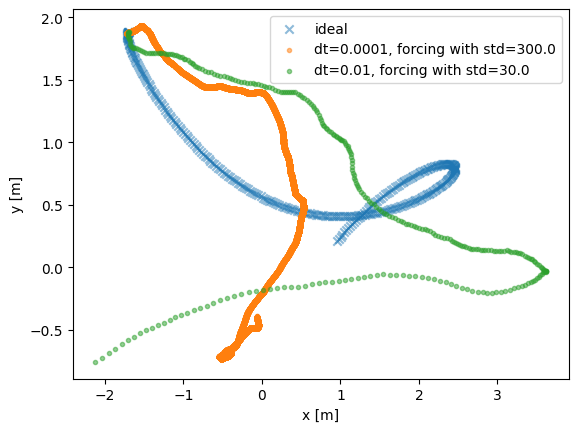

In [47]:
plt.scatter(positions[:,0], positions[:,1], marker="x", alpha=0.5, label="ideal")
A = 3 #[m/s^(3/2)] proportion constant (called acceleration noise spectral density)

for dt in [0.0001, 0.01]:
    N = int(3/dt) #remember to update number of points
    positions_w_rf = np.empty((N, 2))
    velocities_w_rf = np.empty((N, 2))

    positions_w_rf[0] = positions[0] 
    velocities_w_rf[0] = velocities[0]

    a_std = A/np.sqrt(dt) # this gives the correct results

    for i in range(N-1):
        acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
        positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
        velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label=f"dt={dt}, forcing with std={a_std}")

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

## 3. Measuring and filtering

### 3.1 Position only measuremnt (as in GPS or star tracker)

Text(0, 0.5, 'y [m]')

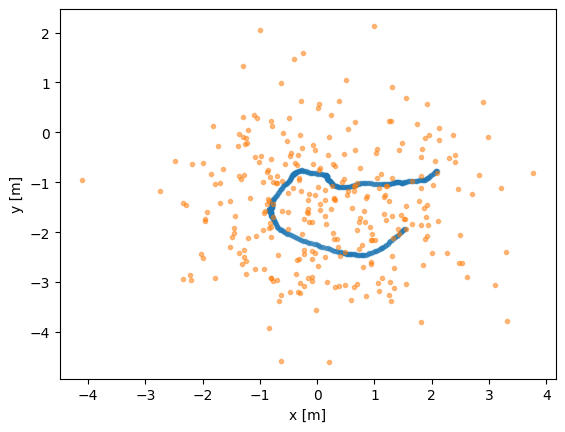

In [13]:
positions_m = np.empty((N, 2)) #m for measured
sigma_xy = 1 #[m] measurement error (1 sigma)
    
for i in range(N):
    positions_m[i] = positions_w_rf[i] + np.random.normal(0, sigma_xy, positions_w_rf[i].shape)

#equivalant code:
#positions_m = np.random.normal(0, xy_std, positions_w_rf.shape)

plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label="true")
plt.scatter(positions_m[:,0], positions_m[:,1], marker=".", alpha=0.5, label="measured")
plt.xlabel("x [m]")
plt.ylabel("y [m]")


Also plot position and error as a function of time

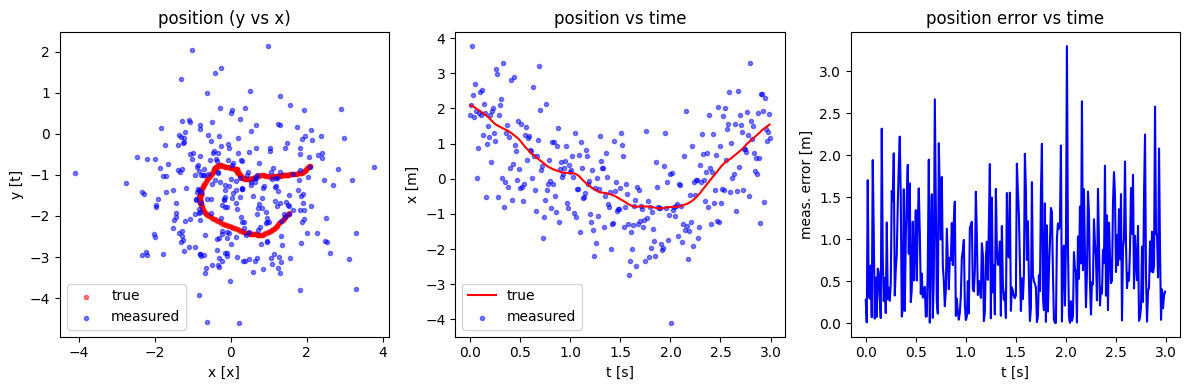

In [14]:
plt.figure(figsize=(12,4)) #make figure larger
times = np.arange(N)*dt #an array of times [s]

plt.subplot(131) #first subplot of of 3 columns (one row)
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label="true", color="r")
plt.scatter(positions_m[:,0], positions_m[:,1], marker=".", alpha=0.5, label="measured", color="b")
plt.legend()
plt.xlabel("x [x]")
plt.ylabel("y [t]")
plt.title("position (y vs x)")
plt.subplot(132)
plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.scatter(times, positions_m[:,0], label="measured", color="b", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")
plt.subplot(133)
plt.plot(times, np.abs(positions_m[:,0] - positions_w_rf[:,0]), color="b")
plt.xlabel("t [s]")
plt.ylabel("meas. error [m]")
plt.title("position error vs time")
plt.tight_layout()

### 3.2 Naive filtering
filtering $\approx$ estiamting the true state given all *prior* measurement

Text(0, 0.5, 'y [m]')

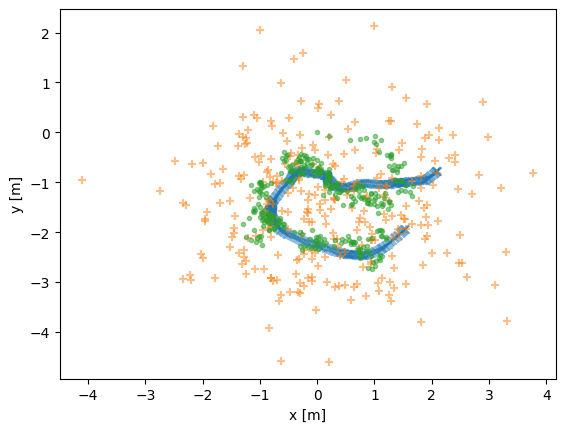

In [15]:
positions_est = np.zeros((N, 2)) #est for estiamted; assume initial estiamte is (0,0) for lack of better information
K = 0.1 #gain

for i in range(N-1):
    positions_est[i+1] = K*positions_m[i+1] + (1-K)*positions_est[i]

plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker="x", alpha=0.5, label="true")
plt.scatter(positions_m[:,0], positions_m[:,1], marker="+", alpha=0.5, label="measured")
plt.scatter(positions_est[:,0], positions_est[:,1], marker=".", alpha=0.5, label="estimated")
plt.xlabel("x [m]")
plt.ylabel("y [m]")

Estimation error quickly converges to a relatively small value.
K trades-off error and lag.

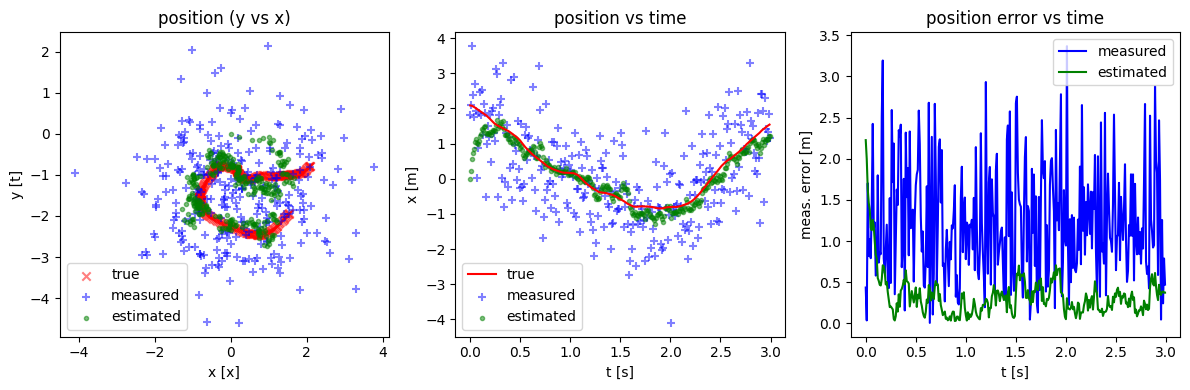

In [16]:
positions_est = np.zeros((N, 2)) #est for estiamted; assume initial estiamte is (0,0) for lack of better information
K = 0.1 #gain

for i in range(N-1):
    positions_est[i+1] = K*positions_m[i+1] + (1-K)*positions_est[i]

RMS_error_m = np.linalg.norm(positions_m - positions_w_rf, axis=1)
RMS_error_est = np.linalg.norm(positions_est - positions_w_rf, axis=1)


plt.figure(figsize=(12,4))

plt.subplot(131)
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker="x", alpha=0.5, label="true", color="r")
plt.scatter(positions_m[:,0], positions_m[:,1], marker="+", alpha=0.5, label="measured", color="b")
plt.scatter(positions_est[:,0], positions_est[:,1], marker=".", alpha=0.5, label="estimated", color="g")
plt.legend()
plt.xlabel("x [x]")
plt.ylabel("y [t]")
plt.title("position (y vs x)")
plt.subplot(132)
plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.scatter(times, positions_m[:,0], label="measured", color="b", marker="+", alpha=0.5)
plt.scatter(times, positions_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")
plt.subplot(133)
plt.plot(times, RMS_error_m, label="measured", color="b")
plt.plot(times, RMS_error_est, label="estimated", color="g")
plt.xlabel("t [s]")
plt.ylabel("meas. error [m]")
plt.title("position error vs time")
plt.legend()
plt.tight_layout()

### 3.3 Velocity estimation is poor with naive filtering

(-19.108466212816868, 19.84845798799792)

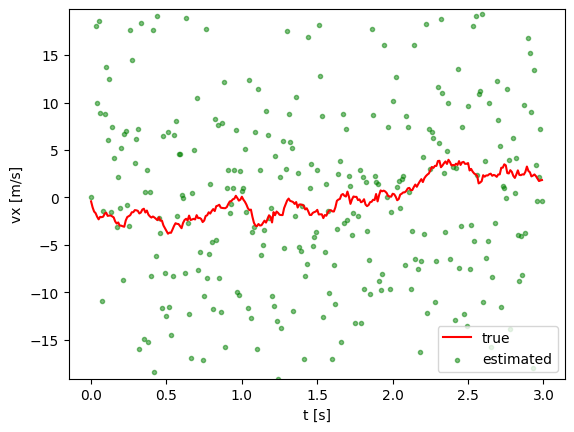

In [17]:
velocities_est = np.zeros((N, 2))

for i in range(N-1):
    velocities_est[i+1] = (positions_est[i+1] - positions_est[i])/dt #numerical time derivate "magnifies errors by 1/dt"

#equivalent code:
#velocities_est[1:] = (positions_est[1:] - positions_est[:-1])/dt


plt.plot(times, velocities_w_rf[:,0], label="true", color="r")
plt.scatter(times, velocities_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")
plt.ylim(velocities_w_rf[:,0].min()*5, velocities_w_rf[:,0].max()*5)


quantiying the errors:

In [18]:
def RMS(error_time_series):
    return np.sqrt(np.mean(np.sum(error_time_series**2, axis=-1)))

print(f"RMS postion error {RMS(positions_est - positions_w_rf):.2f} m")
print(f"RMS velocity error {RMS(velocities_est - velocities_w_rf):.2f} m/s")

RMS postion error 0.43 m
RMS velocity error 14.88 m/s


### 3.4 State estimation
utilizing the equations of motion for better estimation

RMS postion error 0.48 m
RMS velocity error 4.50 m/s


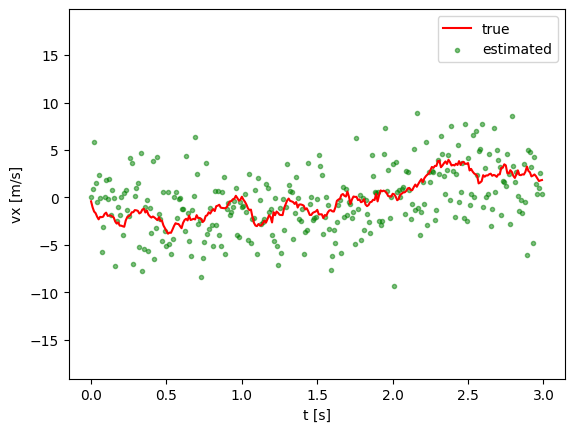

In [ ]:
positions_est = np.zeros((N, 2))
velocities_est = np.zeros((N, 2))

K_pos = 0.1 #position gain
K_vel = 0.03 #velocity gain (carefully picked)

for i in range(N-1):
    #estimate acceleration using the equation of motion
    acceleration_est = get_acceleration(positions_est[i], velocities_est[i], i*dt)

    #predict position and velocity based on estimates
    position_prediction = positions_est[i] + velocities_est[i]*dt
    velocity_prediction = velocities_est[i] + acceleration_est*dt

    #old velocity estimate
    velocity_num_der = (positions_m[i+1] - positions_m[i])/dt
    #NOTE: if velocity is measured, take a weighted average fo the velocity measurement and the numerical derivative

    #update position and velocity based on measurement AND analytic prediction
    positions_est[i+1] = K_pos*positions_m[i+1] + (1-K_pos)*position_prediction
    velocities_est[i+1] = K_vel*velocity_num_der + (1-K_vel)*velocity_prediction



plt.plot(times, velocities_w_rf[:,0], label="true", color="r")
plt.scatter(times, velocities_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")
plt.ylim(velocities_w_rf[:,0].min()*5, velocities_w_rf[:,0].max()*5)

print(f"RMS postion error {RMS(positions_est - positions_w_rf):.2f} m")
print(f"RMS velocity error {RMS(velocities_est - velocities_w_rf):.2f} m/s")

### 3.5 How to choose gains using an Extended Kalman Filter (advanced)

#### 3.5.1 Rewrite as a state equation

$\mathbf{s}=\begin{bmatrix}x\\
y\\
v_{x}\\
v_{y}
\end{bmatrix}$

$\dot{\mathbf{s}}=\begin{bmatrix}\dot{x}\\
\dot{y}\\
\ddot{x}\\
\ddot{y}
\end{bmatrix}=\begin{bmatrix}v_{x}\\
v_{y}\\
a_{x}\\
a_{y}
\end{bmatrix}=\begin{bmatrix}v_{x}\\
v_{y}\\
a(r^{2}-x^{2}-y^{2})x-bv_{y}\\
a(r^{2}-x^{2}-y^{2})y+bv_{x}
\end{bmatrix}$

check that this gives the same simulated results with

$\mathbf{s}(t+\Delta t)\approx\mathbf{s}(t)+\dot{\mathbf{s}}(t)\Delta t $

or simply

$\mathbf{s}_{i+1} = \mathbf{f}(\mathbf{s}_i)$

In [20]:
def f(s, dt):
    x,y,vx,vy = s

    ax = a*(r2 - x**2 - y**2)*x - b*vy
    ay = a*(r2 - x**2 - y**2)*y + b*vx

    return s + np.array([vx, vy, ax, ay])*dt

True


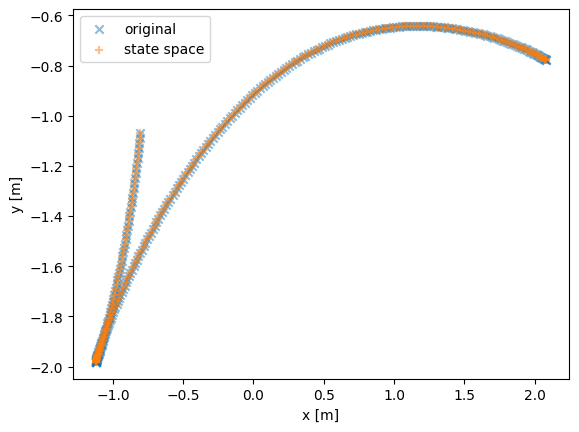

In [21]:
plt.scatter(positions[:,0], positions[:,1], marker="x", alpha=0.5, label="original")

dt = 0.01
N = len(positions)

states = np.empty((N,4))
states[0,0:2] = positions[0] #same initial conditions
states[0,2:4] = velocities[0]

for i in range(N-1):
    states[i+1] = f(states[i], dt)

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

plt.scatter(states[:,0], states[:,1], marker="+", alpha=0.5, label="state space")
plt.legend()

print(np.allclose(positions, states[:,:2])) #check if numericaly close


#### 3.5.2 Find the linearized equation

$\mathbf{s}_{i+1}\approx F_{i}\mathbf{s}_{i})$

where $F_{i}=\left.\frac{\partial\mathbf{f}}{\partial\mathbf{s}}\right|_{\mathbf{s}_{i}}$ is the Jacobian at $\mathbf{s}_{i}$

the Jacobian is given by

$\frac{\partial\mathbf{f}}{\partial\mathbf{s}}=\begin{bmatrix}\frac{\partial(x+v_{x}dt)}{\partial x} & \cdots & \cdots & \frac{\partial(x+v_{x}dt)}{\partial v_{y}}\\
\frac{\partial(y+v_{y}dt)}{\partial x} & \frac{\partial(y+v_{y}dt)}{\partial y} & \cdots\\
\vdots &  & \ddots\\
 &  &  & \frac{\partial(v_{y}+a_{y}dt)}{\partial v_{y}}
\end{bmatrix}=\begin{bmatrix}1 & 0 & dt & 0\\
0 & 1 & 0 & dt\\
a(r^{2}-3x^{2}-y^{2})dt & -2axydt & 1 & -bdt\\
-2axydt & a(r^{2}-x^{2}-3y^{2})dt & bdt & 1
\end{bmatrix}$

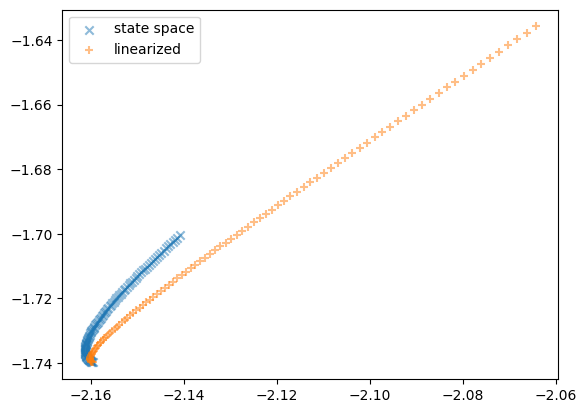

In [22]:
dt = 0.001
t_end = 0.1
N = int(t_end/dt)

def f(s, dt):
    x,y,vx,vy = s

    ax = a*(r2 - x**2 - y**2)*x - b*vy
    ay = a*(r2 - x**2 - y**2)*y + b*vx

    return s + np.array([vx, vy, ax, ay])*dt

def F(s, dt):
    x,y,vx,vy = s
    
    return np.array([[                        1,                         0,   dt,       0], \
                     [                        0,                         1,    0,      dt], \
                     [a*(r2 - 3*x**2 - y**2)*dt,               -2*a*y*x*dt,    1,   -b*dt], \
                     [              -2*a*x*y*dt, a*(r2 - x**2 - 3*y**2)*dt, b*dt,       1]])

states = np.empty((N,4))
states_ln = np.empty((N,4))

states[0,0:2] = np.random.normal(0,3,2)
states[0,2:4] = np.random.normal(0,0.3,2)
states_ln[0] = states[0] #same initial conditions

for i in range(N-1):
    states[i+1]    = f(states[i], dt)
    states_ln[i+1] = F(states_ln[i], dt).dot(states_ln[i])

plt.scatter(states[:,0], states[:,1], marker="x", alpha=0.5, label="state space")
plt.scatter(states_ln[:,0], states_ln[:,1], marker="+", alpha=0.5, label="linearized")
plt.legend()


#### 3.5.3 Add process noise in state space

$\mathbf{s}_{i+1}=\mathbf{f}(\mathbf{s}_{i})+\mathbf{n}_{i}$ where $\mathbf{n}_{i}$ is normally distributed noise

In (2.1) we have:

random_acceleration = np.random.normal(0, a_std, acceleration.shape)

with a_std = A/np.sqrt(dt)

and then the random acceleration is multiplied by dt.

This is equivalent to adding np.random.normal(0, A*np.sqrt(dt), acceleration.shape) to the vecolity at each time step.

(the velocity makes random steps with standard deviation of A*np.sqrt(dt))

No forcing was directly applied to position.


In [23]:
def realistic_f(s, A, dt):
    position_forcing = np.zeros(2)
    velcoity_forcing = np.random.normal(0, A*np.sqrt(dt), 2)

    forcing = np.concatenate([position_forcing, velcoity_forcing])

    return f(s, dt) + forcing

comparing to previous implementation (sanity check)

Text(0, 0.5, 'y [m]')

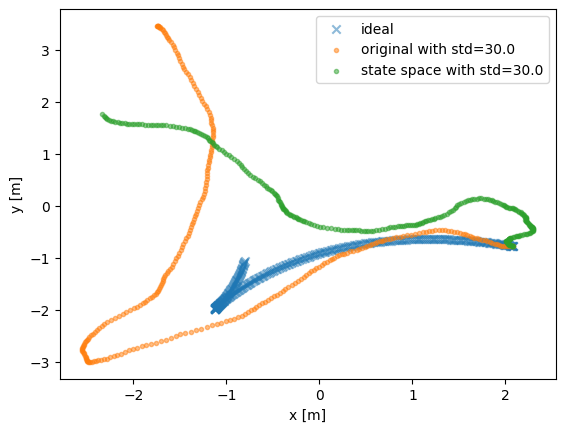

In [24]:
plt.scatter(positions[:,0], positions[:,1], marker="x", alpha=0.5, label="ideal")
A = 3 #[m/s^(3/2)] proportion constant (called acceleration noise spectral density)

dt = 0.01
N = int(3/dt) #remember to update number of points
positions_w_rf = np.empty((N, 2))
velocities_w_rf = np.empty((N, 2))
states_w_rf = np.empty((N,4))

states_w_rf[0,:2] = positions_w_rf[0] = positions[0] 
states_w_rf[0,2:4] = velocities_w_rf[0] = velocities[0]

a_std = A/np.sqrt(dt)

for i in range(N-1):
    acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
    positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
    velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    states_w_rf[i+1] = realistic_f(states_w_rf[i], A, dt)

plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker=".", alpha=0.5, label=f"original with std={a_std}")
plt.scatter(states_w_rf[:,0], states_w_rf[:,1], marker=".", alpha=0.5, label=f"state space with std={a_std}")

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

The general form is 

$\mathbf{w}_{i}\sim{\cal N}\left(\mathbf{0},Q\right)$.

where $Q$ is the $4 \times 4$ covariance matrix

$Q=\begin{bmatrix}0\\
 & 0\\
 &  & A^{2}\Delta t\\
 &  &  & A^{2}\Delta t
\end{bmatrix}$

(the diagonal is the variance of the forcing --  the square of the standard deviation).

The foricng can be slihgtly rewritten (don't forget to run the sanity check above):


In [25]:
def realistic_f(s, A, dt):
    Q = np.diag([0, 0, A**2*dt, A**2*dt])
    w = np.random.multivariate_normal(np.zeros(4), Q)

    return f(s, dt) + w

#### 3.5.4 Rewrite the measurement equation and noise

$\mathbf{z}_i = \mathbf{h}(\mathbf{s}_{i})  + \mathbf{v}_i$

Previously we had

$\mathbf{h}(\mathbf{s}_{i})=\begin{bmatrix}x\\
y
\end{bmatrix}$

This particular measurement equation does not need to be linearized since it can already be written as

$\mathbf{z}_{i}=H\mathbf{s}_{i}+\mathbf{v}_{i}$

with

$H=\begin{bmatrix}1 & 0 & 0 & 0\\
0 & 1 & 0 & 0
\end{bmatrix}$

The two componenets of $\mathbf{v}_i$ were normally distributed with standard deviation $\sigma_{xy}$.

This can be written as

$\mathbf{v}_{i}\sim{\cal N}\left(\mathbf{0},R\right)$

where

$R=\begin{bmatrix}\sigma_{xy}^{2}\\
 & \sigma_{xy}^{2}
\end{bmatrix}$

Compare the code below with (3.1):


Text(0, 0.5, 'y [m]')

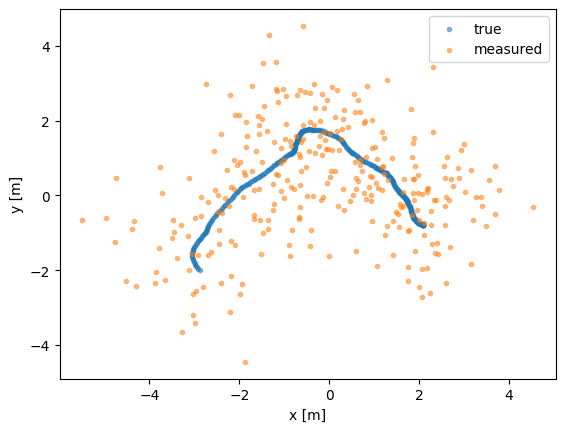

In [26]:
A = 3 #[m/s^(3/2)] proportion constant (called acceleration noise spectral density)

dt = 0.01
N = int(3/dt) #remember to update number of points
states_w_rf = np.empty((N,4))

states_w_rf[0,:2] = positions[0] 
states_w_rf[0,2:4] = velocities[0]
measurements = np.zeros((N,2))

H = np.array([[1,0,0,0], [0,1,0,0]])
R = np.eye(2)*sigma_xy**2

a_std = A/np.sqrt(dt) #[m/s^2] fixed acceleration (this gives wrong results)

for i in range(N):
    if i < N - 1:
        states_w_rf[i+1] = realistic_f(states_w_rf[i], A, dt)

    measurements[i] = H.dot(states_w_rf[i]) + np.random.multivariate_normal(np.zeros(2), R)

plt.scatter(states_w_rf[:,0], states_w_rf[:,1], marker=".", alpha=0.5, label=f"true")
plt.scatter(measurements[:,0], measurements[:,1], marker=".", alpha=0.5, label="measured")

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

#### 3.5.5 Define uncertaity in the initial condition

We had

position_0 = np.random.normal(0,3,2)
velocity_0 = np.random.normal(0,0.3,2)

there for

$\mathbf{s}_{0}\sim{\cal N}\left(\mathbf{0},P_{0|0}\right)$


where

$P_{0|0}=\begin{bmatrix}3^{2}\\
 & 3^{2}\\
 &  & 0.3^{2}\\
 &  &  & 0.3^{2}
\end{bmatrix}$

#### 3.5.6 the Apply Kalman Filter equations

The *estimate* of the state is denoted with a "hat",  $\hat{\mathbf{s}}$. The state $\mathbf{s}$ is *unknown* to the estimator; it's only know in simulation or not at all (when deployed).

In our case, teh estimate starts at zero $\hat{\mathbf{s}}_{0|0} = \mathbf{0}$.

It is advanced in two steps.

a) The next state $\hat{\mathbf{s}}_{i+1|i}$ is predicted based on the previous state $\hat{\mathbf{s}}_{i|i}$:

$\hat{\mathbf{s}}_{i+1|i}=\mathbf{f}(\hat{\mathbf{s}}_{i|i})$

The uncertainty in the predicted state alos needs to be propagated forward:

$P_{i+1|i}=F_{i}P_{i|i}F_{i}^{T}+Q$

b) The next estimate $\hat{\mathbf{s}}_{i+1|i+1}$ is updated based on the pediction $\hat{\mathbf{s}}_{i+1|i}$ and the measurement $\mathbf{z_{i+1}}$:

First, compute the gain (Kalamn gain),

$K_{i+1} = P_{i+1|i}H^{T}S^{-1}_{i+1}$

where

$S_{i+1} = HP_{i+1|i}H^{T} + R$.

Then update the state

$\hat{\mathbf{s}}_{i+1|i+1}=\hat{\mathbf{s}}_{i+1|i}+K_{i+1}\left(\mathbf{z}_{i+1}-\mathbf{h}\left(\hat{\mathbf{s}}_{i+1|i}\right)\right)$,

and finally, update the convariance matrix

$P_{i+1|i+1} = P_{i+1|i+1} - K_{i+1}HP_{i+1|i}$.

Text(0, 0.5, 'y [m]')

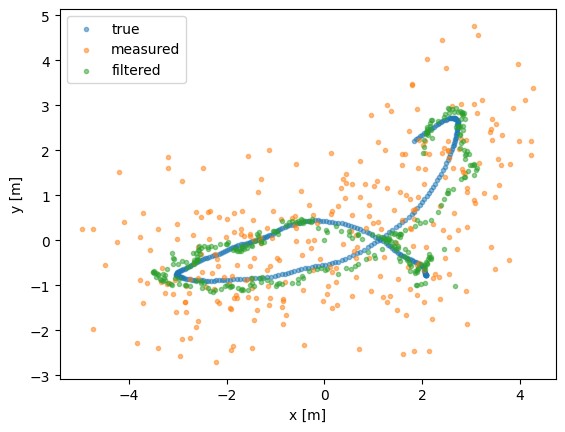

In [27]:
A = 3 #[m/s^(3/2)] proportion constant (called acceleration noise spectral density)

dt = 0.01
N = int(3/dt) #remember to update number of points
states_w_rf = np.empty((N,4))
states_est = np.empty((N,4)) #est for estimate

states_w_rf[0,:2] = positions[0] 
states_w_rf[0,2:4] = velocities[0]

states_est[0] = 0 #this is the prior

measurements = np.zeros((N,2))

P = np.diag([3**2, 3**3, 0.3**2, 0.3**2])
Q = np.diag([0, 0, A**2*dt, A**2*dt])

a_std = A/np.sqrt(dt) #[m/s^2] fixed acceleration (this gives wrong results)

for i in range(N):
    state_pred = f(states_est[i], dt)
    F_est = F(states_est[i], dt) #since the estimator doens't know the real state
    P_pred = F_est.dot(P).dot(F_est.T) + Q

    S = H.dot(P_pred).dot(H.T) + R
    K = P_pred.dot(H.T).dot(np.linalg.inv(S))
    P = P_pred - K.dot(H).dot(P_pred)

    measurements[i] = H.dot(states_w_rf[i]) + np.random.multivariate_normal(np.zeros(2), R)

    if i < N - 1:
        states_w_rf[i+1] = realistic_f(states_w_rf[i], A, dt)
        states_est[i+1] = state_pred + K.dot(measurements[i] - H.dot(state_pred))

plt.scatter(states_w_rf[:,0], states_w_rf[:,1], marker=".", alpha=0.5, label=f"true")
plt.scatter(measurements[:,0], measurements[:,1], marker=".", alpha=0.5, label="measured")
plt.scatter(states_est[:,0], states_est[:,1], marker=".", alpha=0.5, label="filtered")

plt.legend()
plt.xlabel("x [m]")
plt.ylabel("y [m]")

velocity estimates are much better now:

RMS postion error 0.39 m
RMS velocity error 2.20 m/s


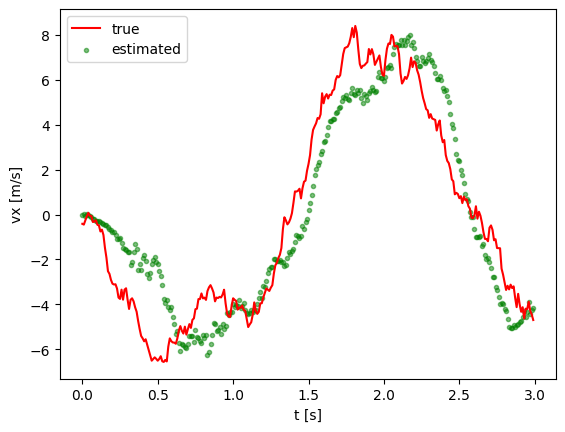

In [28]:
plt.plot(times, states_w_rf[:,2], label="true", color="r")
plt.scatter(times, states_est[:,2], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")

print(f"RMS postion error {RMS(states_est[:,0:2] - states_w_rf[:,0:2]):.2f} m")
print(f"RMS velocity error {RMS(states_est[:,2:4] - states_w_rf[:,2:4]):.2f} m/s")

### 3.6 Different measurements types

#### 3.6.1 Acceleration

Extend you state to include acceleration as well, in 1D, for example:

$\mathbf{s}=\begin{bmatrix}x\\
v_{x}\\
a_{x}
\end{bmatrix}$

and 

$\mathbf{s}(t+\Delta t)\approx\begin{bmatrix}x(t)+v_{x}(t)\Delta t\\
v_{x}(t)+\left(f(x,v_{x})+a_{x}\right)\Delta t\\
n(t)
\end{bmatrix}$

where $f$ is known from the equations of motion and  $n(t)$ is white noise (with properly scaled standard deviation)

#### 3.6.2 Measurements at different cadence (or multiple componenets in general)

Whether using an EKF or not, each measurement $m$ updates the state *estimate* as follows:

$\hat{\mathbf{s}}_{\mathrm{after\:m}}=\hat{\mathbf{s}}_{\mathrm{before\:m}}+K_{\mathrm{m}}\left(\mathbf{z}_{\mathrm{m}}-\mathbf{\mathbf{h}}_{\mathrm{m}}\left(\hat{\mathbf{s}}_{\mathrm{before\:m}}\right)\right)$

where $K_{\mathrm{m}}$ is the gain for that particular measuremnt type ($m$), $\mathbf{z}_{\mathrm{m}}$ is the simulkated measurement (with noise) and $\mathbf{\mathbf{h}}_{\mathrm{m}}\left(\mathbf{s}_{\mathrm{before\:m}}\right)$ is the predicted measurement based on the previous state estimate.

The challenge is apply this update at the right time for each measuremnt and select the gains appropriately (EKF typically gives good results).


## 4. Closing the loop with continous controller (e.g., reaction wheels torque)

### 4.1 Continous control (e.g., reaction wheels)

You can try the control laws such as PID from your controls class.

First, test the controller *as if* the state (position, velcoity) are known.

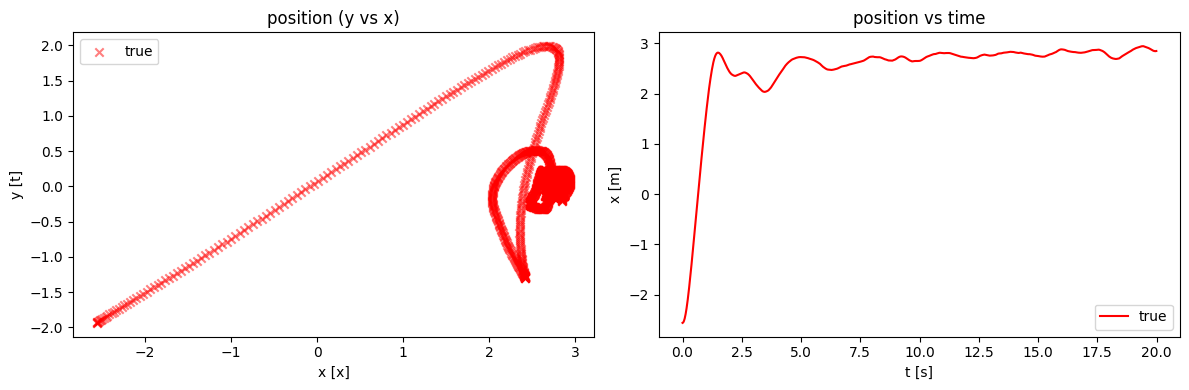

In [29]:
A = 0.3 #[m/s^(3/2)] NOTE: reduced spectal noise
dt = 0.01
a_std = A/np.sqrt(dt)

target_pos = np.array([3,0]) # [m] what state you want to control to

N = int(20/dt) #remember to update number of points
times = np.arange(N)*dt

positions_w_rf = np.empty((N, 2))
velocities_w_rf = np.empty((N, 2))

positions_w_rf[0] = np.random.normal(0,3,2)
velocities_w_rf[0] = np.random.normal(0,0.3,2)

#PID gains (tuned)
K_P = 2
K_I = 1
K_D = 1.2

control = np.zeros(2) #already in units of acceleration for this example only
err_integral = np.zeros(2)

for i in range(N-1):
    # simulated dynamics
    acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
    acceleration_w_rf += control #control added here
    positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
    velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    #control computataion
    err_integral += (positions_w_rf[i+1] - target_pos)*dt
    control = -K_P*(positions_w_rf[i+1] - target_pos) - K_I*err_integral - K_D*velocities_w_rf[i]


plt.figure(figsize=(12,4))

plt.subplot(121)
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker="x", alpha=0.5, label="true", color="r")
plt.legend()
plt.xlabel("x [x]")
plt.ylabel("y [t]")
plt.title("position (y vs x)")
plt.subplot(122)

plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")

plt.tight_layout()

Once the controller is working, add real-world complications such as noisy measurment and actuator saturation.

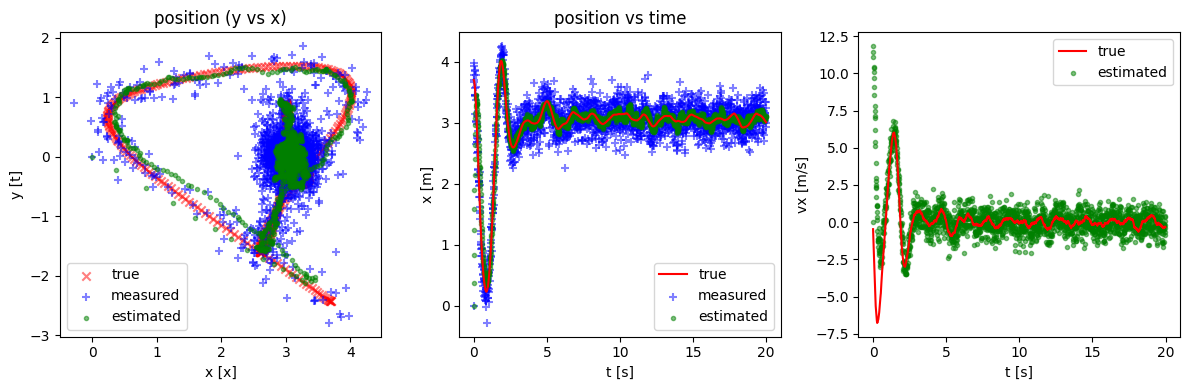

In [32]:
sigma_xy = 0.2 #[m] measurement error (1 sigma)

positions_w_rf[0] = np.random.normal(0,3,2)
velocities_w_rf[0] = np.random.normal(0,0.3,2)

positions_m = np.zeros((N, 2))
   
positions_est = np.zeros((N, 2))
velocities_est = np.zeros((N, 2))

controls_mag = np.zeros(N)
max_control = 100 #m/s^2

target_pos = np.array([3,0])

#PID gains (tuned)
K_P = 2
K_I = 1
K_D = 1.2

control = np.zeros(2) #already in units of acceleration for this example only

for i in range(N-1):
    # simulated dynamics
    acceleration_w_rf = get_realistic_acceleration(positions_w_rf[i], velocities_w_rf[i], i*dt, a_std)
    acceleration_w_rf += control #control added here
    positions_w_rf[i+1] = positions_w_rf[i] + velocities_w_rf[i]*dt
    velocities_w_rf[i+1] = velocities_w_rf[i] + acceleration_w_rf*dt

    #measurement(s)
    positions_m[i+1] = positions_w_rf[i+1] + np.random.normal(0, sigma_xy, positions_w_rf[i+1].shape)

    #estimate acceleration using the equation of motion
    acceleration_est = get_acceleration(positions_est[i], velocities_est[i], i*dt)
    acceleration_est += control #control also added here

    #predict position and velocity based on estimates
    position_prediction = positions_est[i] + velocities_est[i]*dt
    velocity_prediction = velocities_est[i] + acceleration_est*dt

    #old velocity estimate
    velocity_num_der = (positions_m[i+1] - positions_m[i])/dt
    #NOTE: if velocity is measured, take a weighted average fo the velocity measurement and the numerical derivative

    #update position and velocity based on measurement AND analytic prediction
    positions_est[i+1] = K_pos*positions_m[i+1] + (1-K_pos)*position_prediction
    velocities_est[i+1] = K_vel*velocity_num_der + (1-K_vel)*velocity_prediction

    #control computataion
    #IMPORTANT: use estimates here, not simulated position
    err_integral += (positions_est[i+1] - target_pos)*dt
    control = -K_P*(positions_est[i+1] - target_pos) - K_I*err_integral - K_D*velocities_est[i]

    control_mag = np.linalg.norm(control)

    #check if controller is saturated
    if control_mag > max_control:
        control = control*(max_control/control_mag)

    controls_mag[i+1] = np.linalg.norm(control)



plt.figure(figsize=(12,4))

plt.subplot(131)
plt.scatter(positions_w_rf[:,0], positions_w_rf[:,1], marker="x", alpha=0.5, label="true", color="r")
plt.scatter(positions_m[:,0], positions_m[:,1], marker="+", alpha=0.5, label="measured", color="b")
plt.scatter(positions_est[:,0], positions_est[:,1], marker=".", alpha=0.5, label="estimated", color="g")
plt.legend()
plt.xlabel("x [x]")
plt.ylabel("y [t]")
plt.title("position (y vs x)")
plt.subplot(132)

plt.plot(times, positions_w_rf[:,0], label="true", color="r")
plt.scatter(times, positions_m[:,0], label="measured", color="b", marker="+", alpha=0.5)
plt.scatter(times, positions_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("x [m]")
plt.title("position vs time")

plt.subplot(133)
plt.plot(times, velocities_w_rf[:,0], label="true", color="r")
plt.scatter(times, velocities_est[:,0], label="estimated", color="g", marker=".", alpha=0.5)
plt.legend()
plt.xlabel("t [s]")
plt.ylabel("vx [m/s]")


plt.tight_layout()

Fincally, calcualte closed-loop performace

In [33]:
N_last = int(5/dt) #take the last 5 seconds (to make sure the controller converged)

print(f"Standard deviation of closed-loop position {np.std(positions_w_rf[-N_last:] - target_pos[-N_last:]):.2f} [m]")
print(f"Standard deviation of closed-loop velocity {np.std(velocities_w_rf[-N_last:]):.2f} [m/s]")

Standard deviation of closed-loop position 0.09 [m]
Standard deviation of closed-loop velocity 0.28 [m/s]


#### 4.2 Closing the loop with impulsive control (e.g., propulsive bursts)

The assumption here is that equaitons of motion have a closed form solution (e.g., Clohessy–Wiltshire equations)

a) Write a function that, given a target position, current position, and velocity, computes:
<ul>
 <li>the 3D delta-V that changes the object's velcoity such that it reaches the target position (need to invert the equations of motion)</li>

 <li>the time at which the object will be at the target position</li>

 <li>the thrust neccesary to bring the object to rest once it reaches the desired position</li>
</ul>

b) Simulate this two step control *as if* you have the perfect knowledge of the position and velocity:
<ul>
 <li>run the simulation at with a fine time increments</li>

 <li>at a predefined time step, call the function you wrote in (a)</li>

 <li>add the computed delta-V to the object's velocity</li>

 <li>apply delta-V again after the appropriate number of time steps to bring the object to rest</li>

 <li>test your simulation throughouly to make sure it works in this idealized case</li>
 </ul>


c) Add realistic complications (one at a time):
<ul>

 <li>add measuremnt noise and estimation (don't forget to update your estimated velocity with the delta-V)</li>

 <li>add thruster uncertainties such as burn orientation, magnitude</li>

 <li>add thurst saturation and minimum impulse bit</li>

 <li>test thorughouly and measure closed-loop performance</li>
</ul>

d) Improve performance:
<ul>
 <li>update the last burn to use the estimated velocity</li>

 <li>update the code to more than just two impulses (call the funciton from (a) several times)</li>
</ul>